# Prognozowanie anulacji i inteligentny overbooking
### Raport dla Klienta (dane publiczne *Hotel Booking Demand* + elementy syntetyczne)

Notatnik uruchamia **cały projekt** i pokazuje wyniki przeznaczone dla Klienta: diagnozę problemu,
jakość modelu, backtest overbookingu, plan na najbliższe tygodnie, listę rezerwacji do kontaktu,
analizę polityk anulacji, monitoring i business case.

> Elementy oznaczone jako **SYNTETYCZNE** (koszt relokacji, popyt odrzucony w noce wyprzedane,
> efekt kontaktu z gościem, efekt przedpłat) są założeniami - wszystkie znajdują się w `config.py`.

Czas wykonania: ok. 1-2 minuty.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%matplotlib inline
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

import config as C
from src.pipeline import run_all
from src.report import show, write_html, write_excel

R = run_all(as_of=C.DEMO_AS_OF)      # cały pipeline: dane -> modele -> backtest -> plan -> raport
T, F = R["tables"], R["figures"]

[   0.0s] 1/9 Wczytanie i czyszczenie danych


[   1.3s] 2/9 Migawki bez wycieku danych + trening modeli


  migawki: train=204,602  valid=134,831  test=175,763
  trenuję regresję logistyczną ...


  trenuję LightGBM ...


[  18.6s] 3/9 Wyjaśnialność (SHAP)


...

[  63.9s] 5/9 Backtest polityk overbookingu (2017)


[  65.8s] 6/9 Eksperyment A/B działań prewencyjnych [syntetyczny]
[  66.0s] 7/9 Analiza segmentów i polityk


[  66.2s] 8/9 Plan overbookingu i lista ryzyka na dzień 2017-06-15


[  67.5s] 9/9 Monitoring i business case


[  73.4s] Gotowe.


## 1. Podsumowanie dla zarządu

,Wartość
Korzyść netto rocznie [EUR],118 000 €
Koszt projektu [EUR],30 000 €
ROI w 1. roku,"293,3%"
Okres zwrotu [miesiące],"3,05"
Korzyść na hotel rocznie [EUR],59 000 €


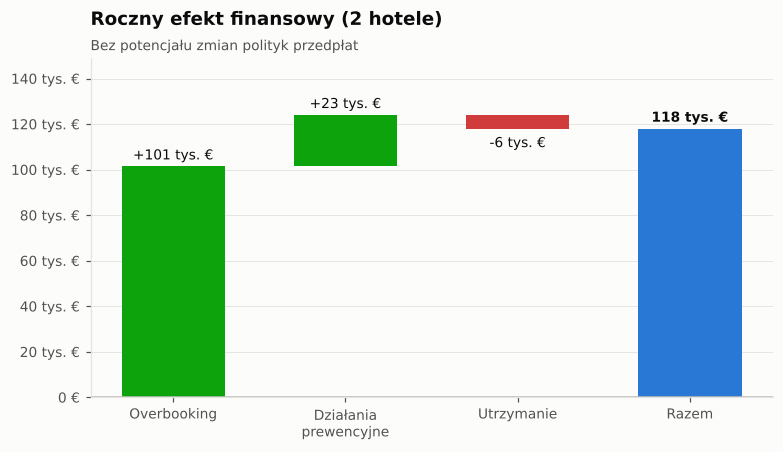

,EUR / rok,Źródło
Pozycja,,
"Overbooking oparty na modelu (backtest, annualizowany)",101 436 €,dane publiczne + syntetyczny popyt odrzucony
Działania prewencyjne wobec ryzykownych rezerwacji,22 563 €,eksperyment SYNTETYCZNY
Koszt utrzymania rozwiązania,-6 000 €,założenie
RAZEM (bez zmian polityk),118 000 €,
Dodatkowo: potencjał zmian polityk przedpłat (do weryfikacji testem),131 684 €,"symulacja what-if, SYNTETYCZNE założenia"
Dla porównania: górna granica overbookingu (wyrocznia),274 538 €,backtest


In [2]:
show(T["kpi"])
show(F["business"])
show(T["business_items"])

## 2. Diagnoza: skala problemu anulacji
Ile rezerwacji nie kończy się pobytem, kiedy następują anulacje i jak często hotele są pełne.

,Hotel miejski,Resort
Liczba rezerwacji,78 898,39 666
Odsetek anulacji,"40,8%","27,3%"
Odsetek no-show,"1,2%","0,7%"
Odsetek anulacji dokonanych w ostatnich 7 dniach,"12,0%","11,6%"
Śr. wyprzedzenie rezerwacji (dni),110,93
Śr. cena za noc (ADR) [EUR],107 €,92 €
Przychód anulowany późno (<=7 dni) [EUR],1 167 163 €,366 324 €
Przychód utracony przez no-show [EUR],361 170 €,88 311 €


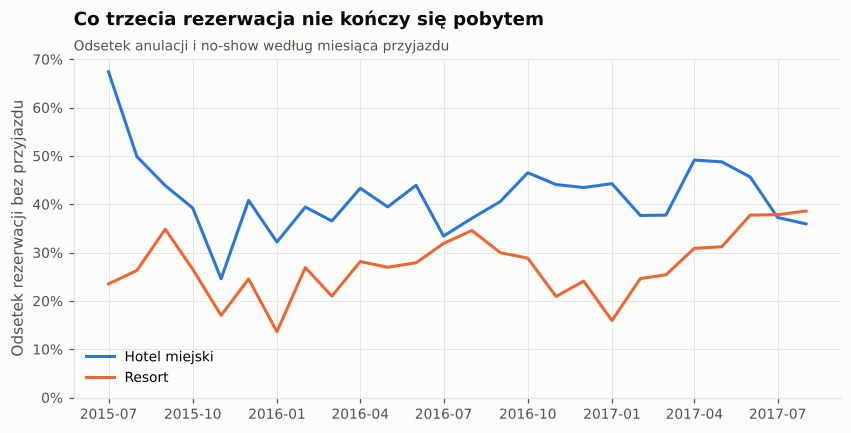

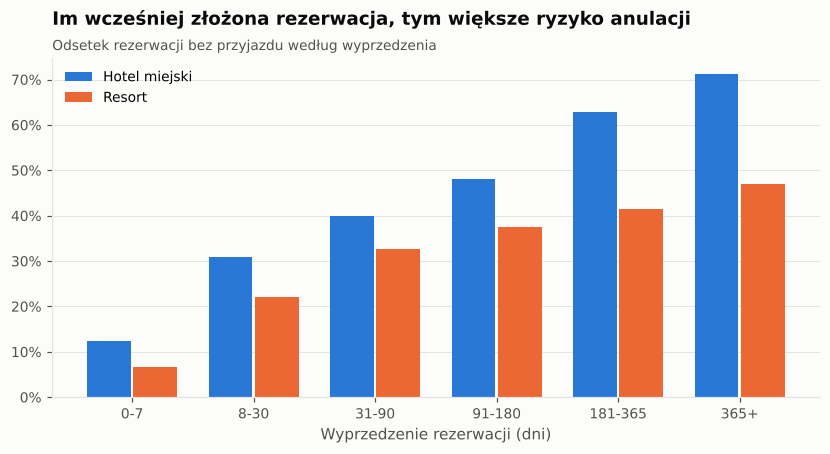

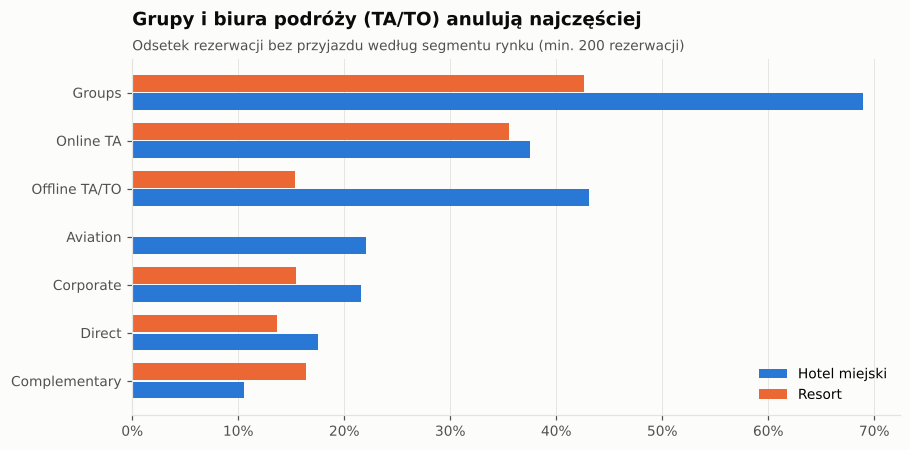

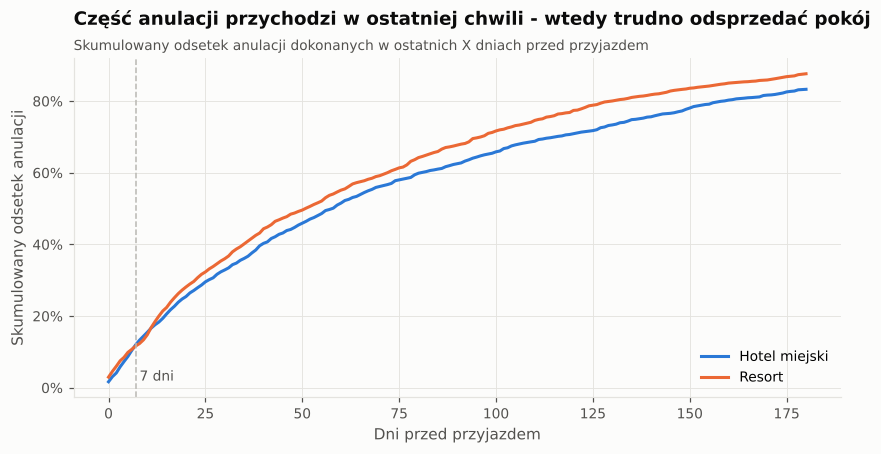

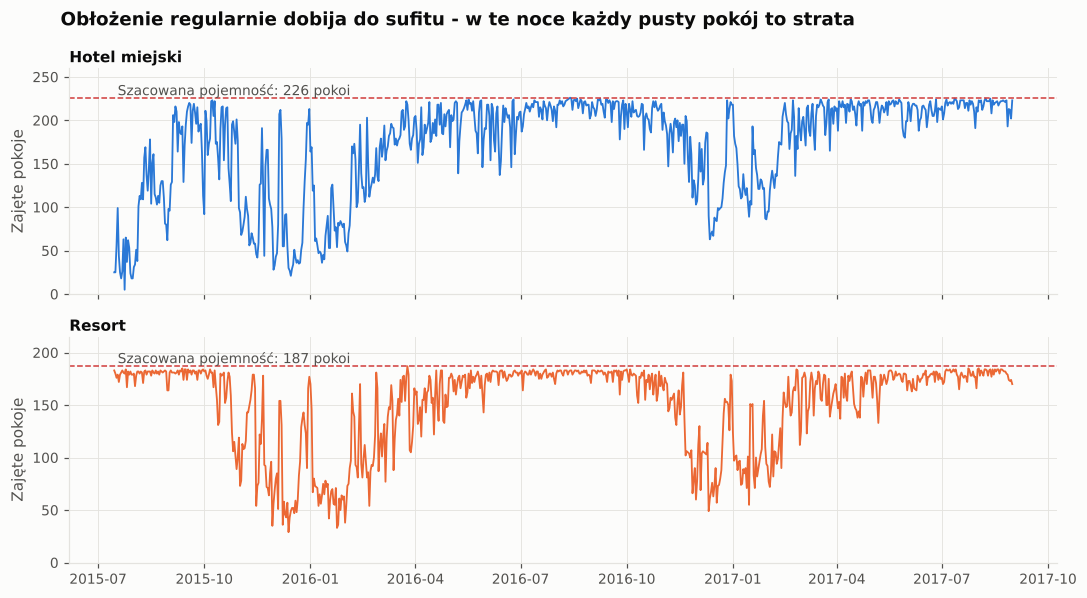

In [3]:
show(T["eda_summary"], decimals={"Liczba rezerwacji": 0, "Śr. wyprzedzenie rezerwacji (dni)": 0}, transpose=True)
show(F["eda_trend"])
show(F["eda_lead"])
show(F["eda_segment"])
show(F["eda_timing"])
show(F["eda_occupancy"])

## 3. Model ryzyka nieprzyjazdu
Model ocenia ryzyko w konkretnym dniu przed przyjazdem (D-0 ... D-180) wyłącznie na podstawie
informacji dostępnych w tym dniu (**migawki bez wycieku danych**). Walidacja czasowa:
trening 07.2015-06.2016, kalibracja 07-12.2016, test 01-08.2017.

,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,Śr. prognoza,Śr. rzeczywista
Heurystyka segmentowa (stan obecny),"0,783","0,378","0,0785","0,2770","2,2%","12,8%","10,7%"
Regresja logistyczna,"0,759","0,420","0,0785","0,2841","1,1%","11,7%","10,7%"
LightGBM (bez kalibracji),"0,802","0,449","0,0752","0,2646","0,2%","10,7%","10,7%"
LightGBM + kalibracja (model docelowy),"0,802","0,438","0,0754","0,2655","0,8%","11,4%","10,7%"


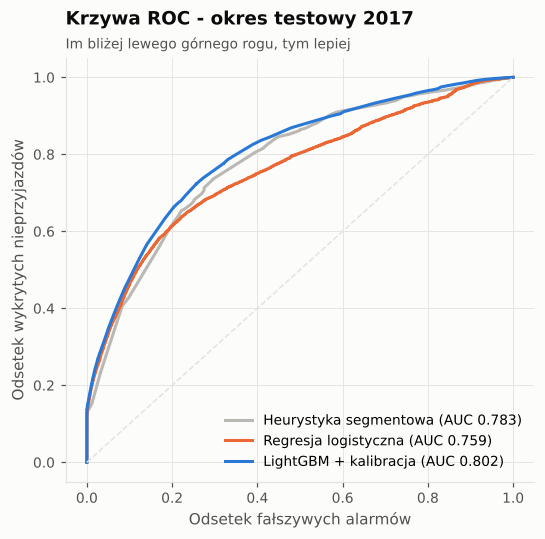

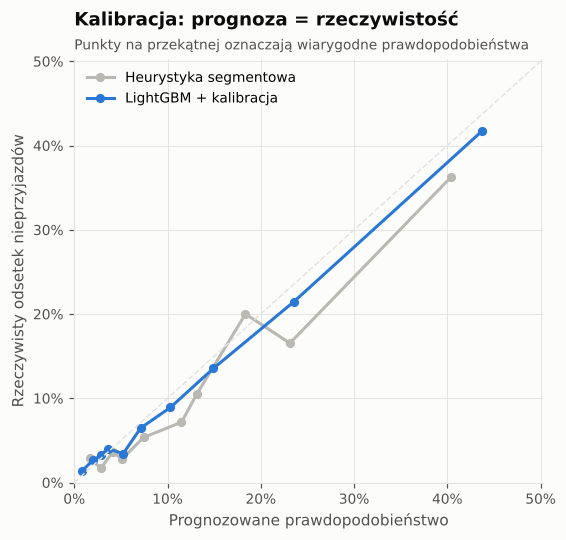

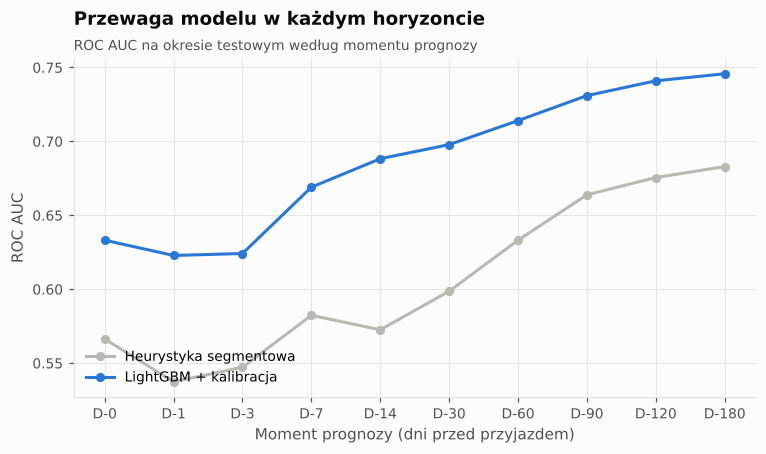

,Liczba rezerwacji,Odsetek nieprzyjazdów,ROC AUC (heurystyka),ROC AUC (LightGBM),Brier (heurystyka),Brier (LightGBM)
Dni do przyjazdu (D-h),,,,,,
0,25 391,"2,4%","0,566","0,633","0,0235","0,0227"
1,23 836,"2,8%","0,537","0,623","0,0274","0,0264"
3,22 447,"3,4%","0,547","0,624","0,0326","0,0321"
7,21 110,"5,3%","0,582","0,669","0,0523","0,0500"
14,20 002,"9,3%","0,573","0,688","0,0810","0,0788"
30,17 816,"14,1%","0,599","0,698","0,1151","0,1086"
60,15 187,"19,4%","0,633","0,714","0,1364","0,1322"
90,12 908,"23,7%","0,664","0,731","0,1543","0,1455"
120,10 724,"27,9%","0,676","0,741","0,1663","0,1606"


In [4]:
show(T["model_comparison"], decimals={"ROC_AUC": 3, "PR_AUC": 3, "Brier": 4, "LogLoss": 4})
show(F["model_roc"])
show(F["model_calibration"])
show(F["model_auc_horizon"])
show(T["model_by_horizon"], decimals={"ROC AUC (heurystyka)": 3, "ROC AUC (LightGBM)": 3,
                                      "Brier (heurystyka)": 4, "Brier (LightGBM)": 4})

## 4. Dlaczego goście nie przyjeżdżają (SHAP)
Wartości SHAP liczone natywnie przez LightGBM. Uwaga: wysokie ryzyko dla depozytu *Non Refund*
to znany artefakt tego zbioru (takie rezerwacje są niemal zawsze anulowane).

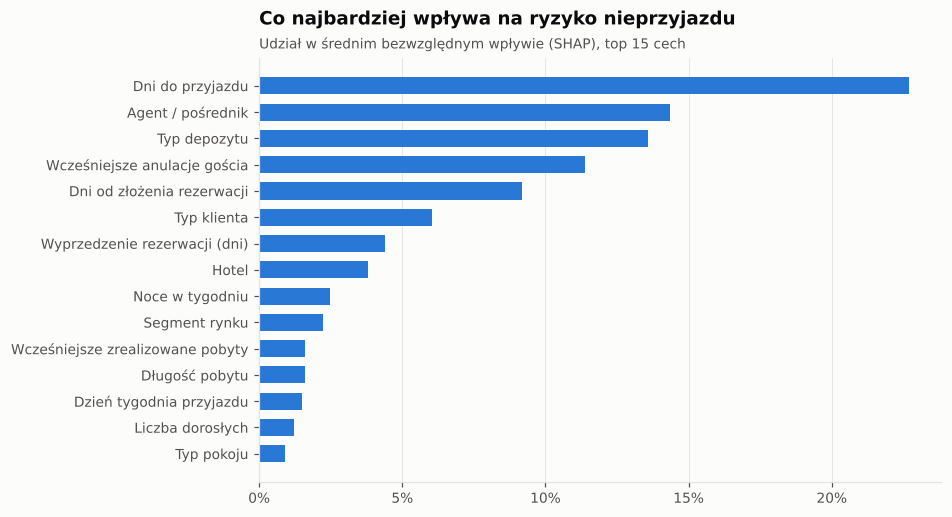

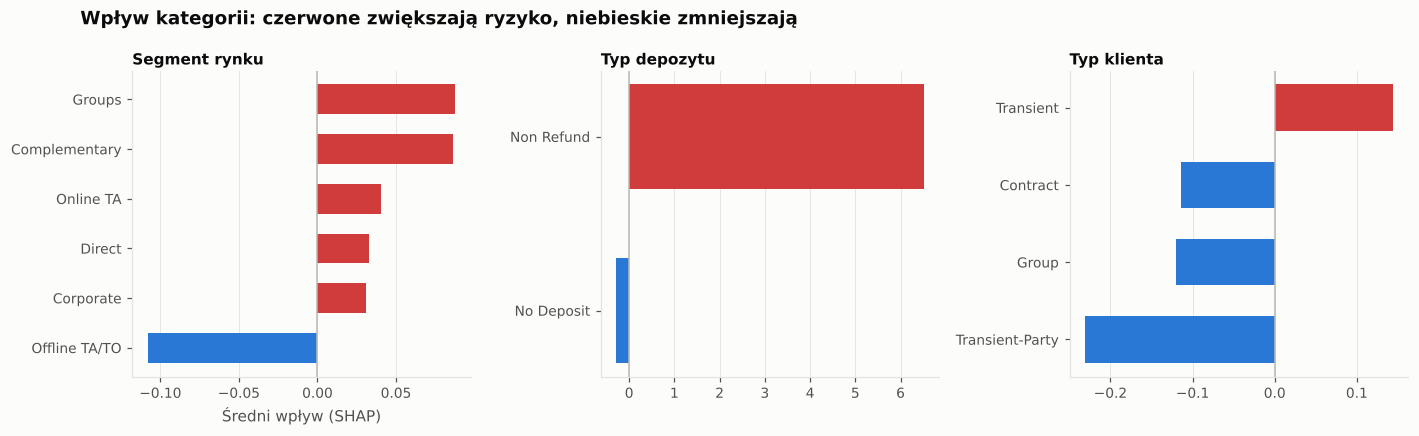

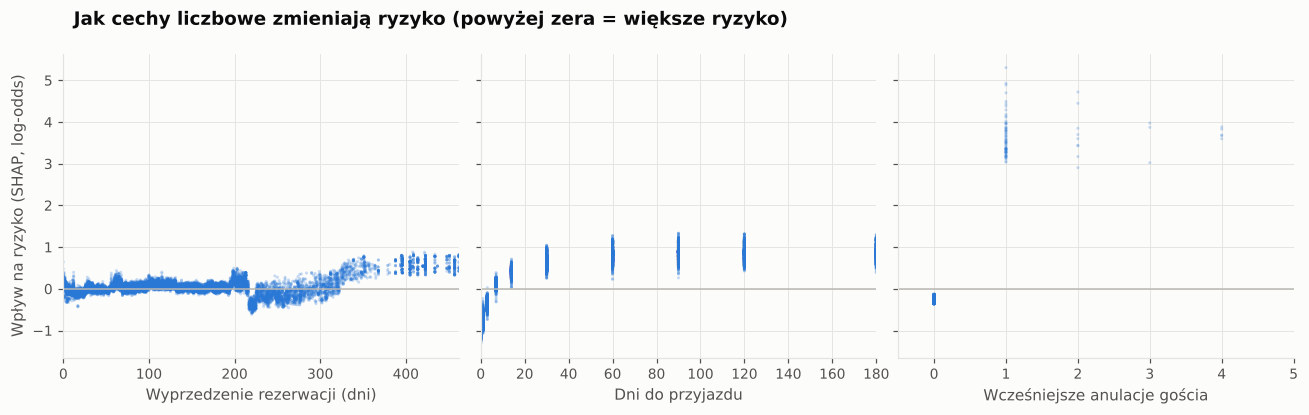

In [5]:
show(F["shap_importance"])
show(F["shap_categories"])
show(F["shap_dependence"])

## 5. Prognoza obłożenia
Prognoza strukturalna (rezerwacje x prawdopodobieństwo przyjazdu + spodziewane nowe rezerwacje)
jest korygowana modelem 2. stopnia; przedziały niepewności z reszt walidacji krzyżowej.

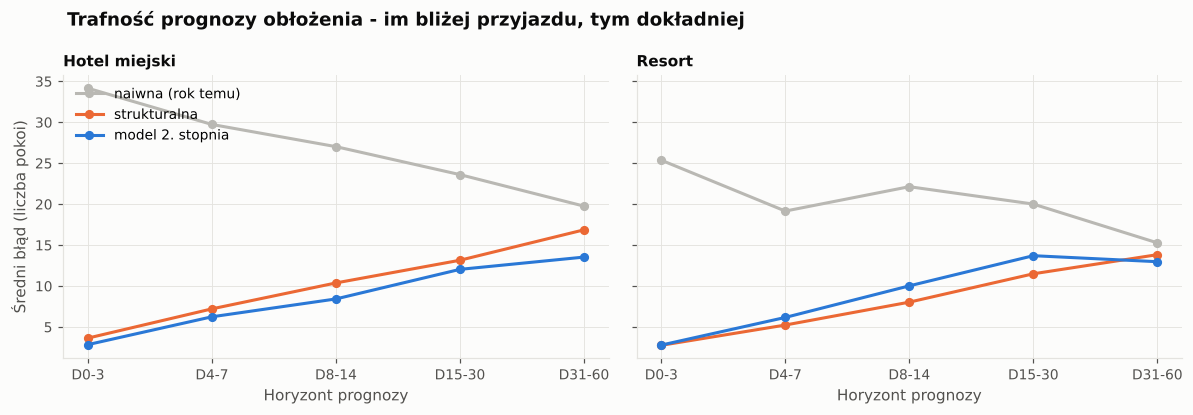

MAE: naiwna (rok temu) MAE: strukturalna MAE: model 2. stopnia Liczba nocy
Hotel        Horyzont                                                                           
City Hotel   D0-3                      34,15              3,64                  2,85          52
             D4-7                      29,73              7,21                  6,24          52
             D8-14                     27,02             10,38                  8,42          91
             D15-30                    23,61             13,15                 12,04         208
             D31-60                    19,76             16,86                 13,53         377
Resort Hotel D0-3                      25,37              2,76                  2,79          52
             D4-7                      19,15              5,23                  6,16          52
             D8-14                     22,13              8,03                 10,02          91
             D15-30                    20,01             11,49                 13,70         208
             D31-60                    15,28             13,83                 12,97         377

In [6]:
show(F["forecast_accuracy"])
show(T["forecast_accuracy"], decimals={"Liczba nocy": 0})

## 6. Overbooking - backtest na 2017 r.
Dla każdej nocy decyzja zapadała na D-3, wyłącznie na podstawie ówczesnej wiedzy.
Porównanie: stan obecny, stały overbooking 5%, model ML, wyrocznia (górna granica).

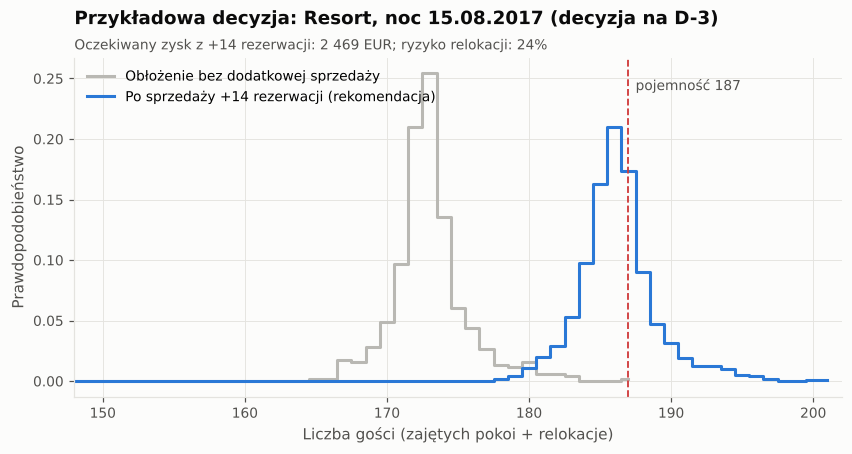

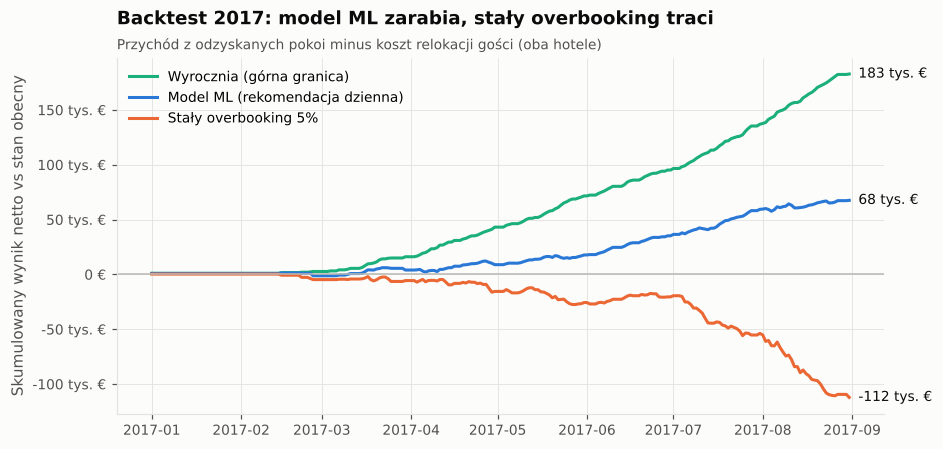

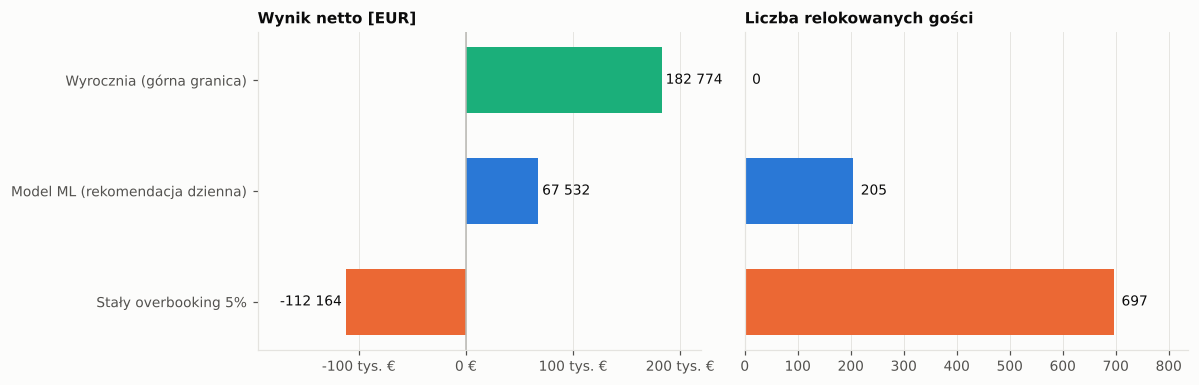

,Odzyskane pokojo-noce,Relokacje gości,Noce z relokacją,Przychód z odzyskanych pokoi [EUR],Koszt relokacji [EUR],Wynik netto [EUR],% potencjału
Polityka,,,,,,,
Bez dodatkowej sprzedaży (stan obecny),0,0,0,0 €,0 €,0 €,"0,0%"
Stały overbooking 5%,1 156,697,160,179 031 €,291 195 €,-112 164 €,"-61,4%"
Model ML (rekomendacja dzienna),977,205,73,149 741 €,82 209 €,67 532 €,"36,9%"
Wyrocznia (górna granica),1 181,0,0,182 774 €,0 €,182 774 €,"100,0%"


In [7]:
show(F["ob_example"])
show(F["ob_cumulative"])
show(F["ob_bars"])
show(T["backtest_summary"])

## 7. Plan overbookingu na kolejne 60 dni (tryb produkcyjny)

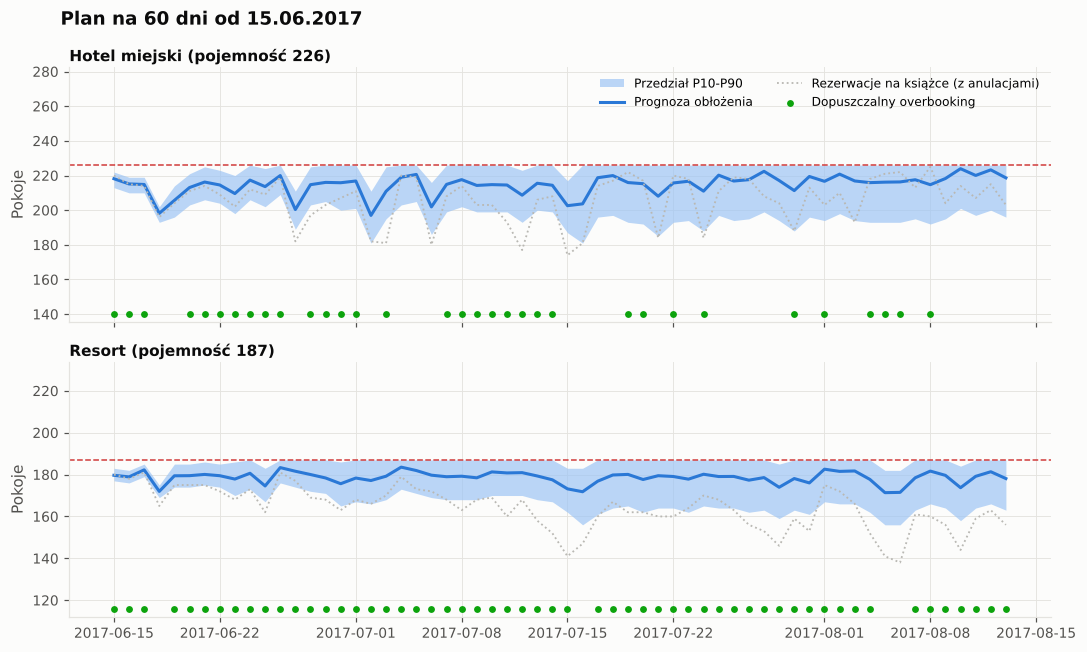

,hotel,night,horizon,capacity,in_house,on_books,forecast,occ_p10,occ_p90,p_full,x_opt,exp_gain,rekomendacja
0,City Hotel,15.06.2017,0,226,142,78,"218,15",213,222,"3,4%",7,"571,18",Dopuść overbooking: +7 rez.
1,City Hotel,16.06.2017,1,226,85,130,"215,14",210,219,"0,9%",10,"954,71",Dopuść overbooking: +10 rez.
2,City Hotel,17.06.2017,2,226,37,177,"214,83",210,219,"0,9%",10,"1 028,94",Dopuść overbooking: +10 rez.
3,City Hotel,18.06.2017,3,226,17,179,"198,18",193,202,"0,0%",29,"3 326,75",Niskie obłożenie - działania sprzedażowe / pro...
4,City Hotel,19.06.2017,4,226,5,199,"205,67",196,214,"0,0%",18,"1 747,76",Niskie obłożenie - działania sprzedażowe / pro...
5,City Hotel,20.06.2017,5,226,1,210,"213,06",203,221,"3,8%",10,"751,38",Dopuść overbooking: +10 rez.
6,City Hotel,21.06.2017,6,226,1,213,"216,23",206,225,"8,2%",6,"376,79",Dopuść overbooking: +6 rez.
7,City Hotel,22.06.2017,7,226,1,208,"214,54",204,223,"6,5%",8,"553,92",Dopuść overbooking: +8 rez.
8,City Hotel,23.06.2017,8,226,1,201,"209,58",198,220,"3,2%",13,"888,97",Dopuść overbooking: +13 rez.
9,City Hotel,24.06.2017,9,226,1,211,"217,35",206,226,"17,9%",4,"98,58",Dopuść overbooking: +4 rez.


In [8]:
show(F["forward_plan"])
plan = T["forward_plan"][["hotel", "night", "horizon", "capacity", "in_house", "on_books", "forecast",
                          "occ_p10", "occ_p90", "p_full", "x_opt", "exp_gain", "rekomendacja"]]
show(plan, max_rows=20)

## 8. Lista rezerwacji wysokiego ryzyka (przyjazd w ciągu 14 dni)

In [9]:
show(T["risk_summary"])
show(T["risk_list"], max_rows=25, decimals={"ID rezerwacji (pseudonim)": 0, "Dni do przyjazdu": 0, "Noce": 0})

,Wartość
Aktywne rezerwacje (przyjazd w ciągu 14 dni),1 424
Do kontaktu telefonicznego,0
Do kontaktu e-mail,227
Oczekiwana liczba nieprzyjazdów,"95,22"
Faktyczna liczba nieprzyjazdów (weryfikacja),61
Przychód zagrożony [EUR],40 377 €


,ID rezerwacji (pseudonim),Hotel,Przyjazd,Dni do przyjazdu,Noce,Kanał,Segment,Depozyt,ADR [EUR],Wartość rezerwacji [EUR],Ryzyko nieprzyjazdu,Przychód zagrożony [EUR],Zalecane działanie,Główne powody ryzyka,Faktycznie nie przyjechał (weryfikacja)
0,71 085,Hotel miejski,28.06.2017,13,1,Corporate,Corporate,No Deposit,100 €,100 €,"30,1%",30 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Dni do przyjazdu: 13; Kanał dystrybucji: Corpo...,1
1,70 574,Hotel miejski,18.06.2017,3,8,TA/TO,Online TA,No Deposit,162 €,1 292 €,"30,1%",389 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A8; Długość pobytu: 8; Hote...,1
2,114 851,Hotel miejski,27.06.2017,12,1,TA/TO,Online TA,No Deposit,99 €,99 €,"30,1%",30 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A9; Dni do przyjazdu: 12; T...,0
3,71 019,Hotel miejski,27.06.2017,12,3,TA/TO,Online TA,No Deposit,126 €,379 €,"28,2%",107 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A9; Dni do przyjazdu: 12; D...,1
4,114 880,Hotel miejski,27.06.2017,12,1,TA/TO,Online TA,No Deposit,99 €,99 €,"28,2%",28 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Dni do przyjazdu: 12; Agent / pośrednik: A9; T...,0
5,114 906,Hotel miejski,27.06.2017,12,1,TA/TO,Online TA,No Deposit,119 €,119 €,"28,2%",34 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A9; Dni do przyjazdu: 12; T...,0
6,114 979,Hotel miejski,29.06.2017,14,1,Direct,Direct,No Deposit,185 €,185 €,"28,2%",52 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A14; Dni do przyjazdu: 14; ...,0
7,114 672,Hotel miejski,23.06.2017,8,2,TA/TO,Online TA,No Deposit,160 €,320 €,"28,2%",90 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Dni od złożenia rezerwacji: 0; Agent / pośredn...,0
8,114 901,Hotel miejski,27.06.2017,12,1,TA/TO,Online TA,No Deposit,99 €,99 €,"28,2%",28 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Dni do przyjazdu: 12; Agent / pośrednik: A9; T...,0
9,115 146,Hotel miejski,28.06.2017,13,4,TA/TO,Online TA,No Deposit,180 €,720 €,"28,2%",203 €,E-mail: prośba o potwierdzenie przyjazdu + ofe...,Agent / pośrednik: A9; Dni do przyjazdu: 13; D...,0


## 9. Działania prewencyjne - test A/B kontaktu z gościem  *(SYNTETYCZNY)*
Efekt kontaktu nałożono syntetycznie na prawdziwe rezerwacje, aby pokazać metodę oceny:
różnica odsetków z przedziałem ufności, efekt w decylach ryzyka i wybór grupy, którą opłaca się kontaktować.

,Wartość
Rezerwacje w eksperymencie,20 002
Odsetek nieprzyjazdów - kontrola,"9,5%"
Odsetek nieprzyjazdów - kontakt,"7,6%"
Spadek (pkt proc.),"1,9%"
95% CI dolny,"1,2%"
95% CI górny,"2,7%"
Rekomendowany próg ryzyka do kontaktu,"0,12"
Decyle do kontaktu,"7, 8, 9, 10"
Odsetek rezerwacji do kontaktu,"41,3%"


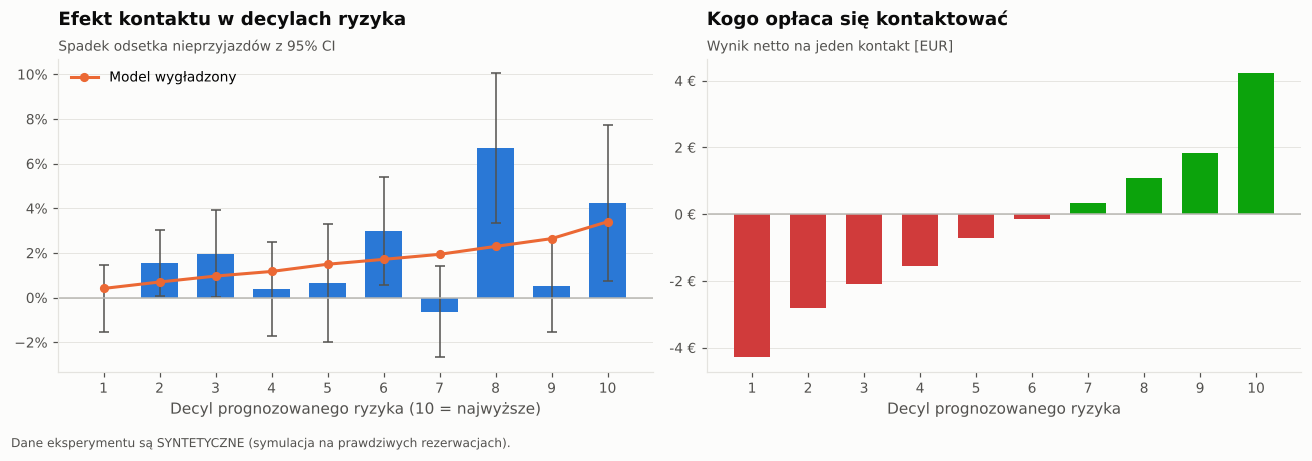

,Śr. prognozowane ryzyko,Rezerwacje,Nieprzyjazdy - kontrola,Nieprzyjazdy - kontakt,Uplift (pkt proc.),CI dolny,CI górny,Uplift - model wygładzony,Śr. przychód z rezerwacji [EUR],Wartość uratowana / kontakt [EUR],Koszt / kontakt [EUR],Wynik netto / kontakt [EUR]
Decyl ryzyka,,,,,,,,,,,,
1,"1,6%",2 001,"2,9%","3,0%","-0,0%","-1,5%","1,4%","0,4%",605 €,1 €,5 €,-4 €
2,"3,2%",2 000,"3,7%","2,2%","1,6%","0,1%","3,0%","0,7%",483 €,2 €,5 €,-3 €
3,"4,9%",2 000,"6,2%","4,2%","2,0%","0,0%","3,9%","1,0%",480 €,2 €,4 €,-2 €
4,"6,4%",2 000,"6,4%","6,1%","0,4%","-1,7%","2,5%","1,2%",474 €,3 €,4 €,-2 €
5,"8,9%",2 000,"10,3%","9,6%","0,7%","-2,0%","3,3%","1,5%",429 €,3 €,4 €,-1 €
6,"10,7%",2 000,"9,8%","6,8%","3,0%","0,6%","5,4%","1,7%",451 €,4 €,4 €,-0 €
7,"12,7%",2 000,"5,4%","6,1%","-0,6%","-2,7%","1,4%","1,9%",425 €,4 €,4 €,0 €
8,"16,1%",2 000,"21,3%","14,6%","6,7%","3,4%","10,1%","2,3%",406 €,5 €,4 €,1 €
9,"19,5%",2 000,"6,3%","5,7%","0,5%","-1,5%","2,6%","2,6%",393 €,5 €,3 €,2 €


In [10]:
show(T["outreach_overall"])
show(F["outreach_uplift"])
show(T["outreach_deciles"])

## 10. Polityki anulacji i przedpłat

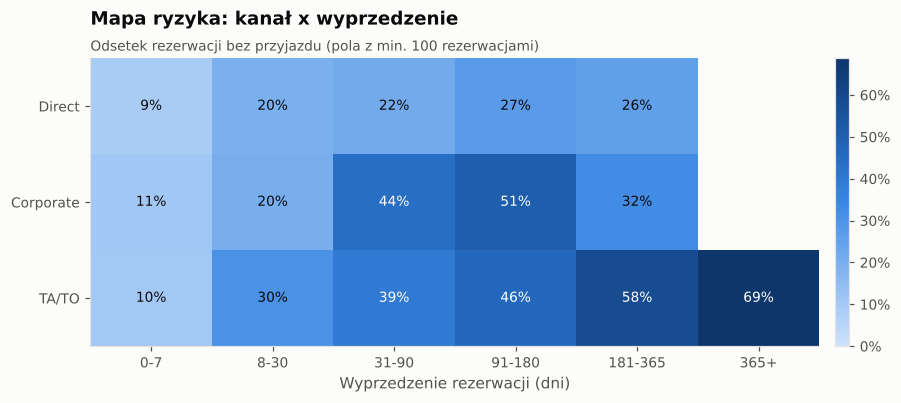

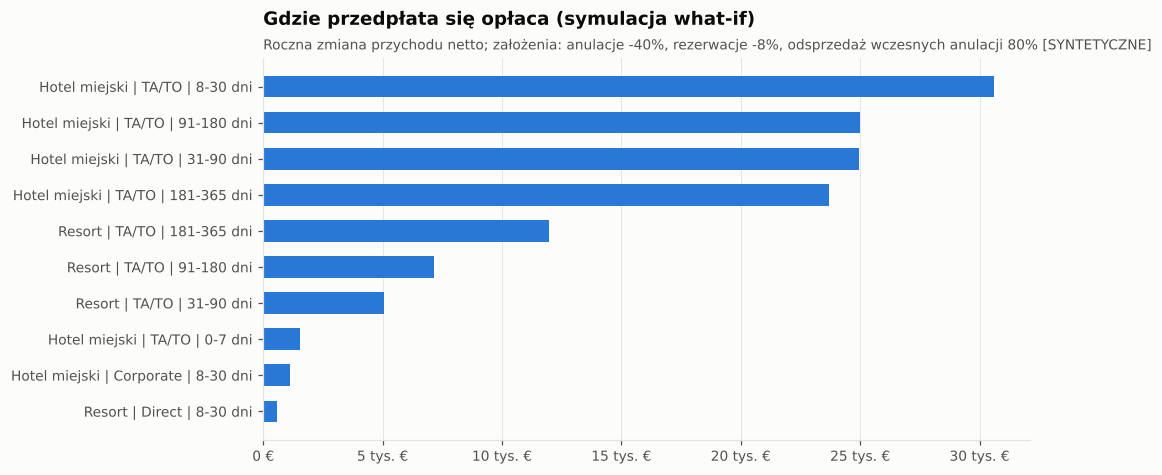

,Hotel,Kanał,Wyprzedzenie (dni),Rezerwacje,Odsetek anulacji,Odsetek późnych anulacji,Zmiana przychodu rocznie [EUR],Rekomendacja
33,Hotel miejski,TA/TO,8-30,9 873,"28,9%","9,1%",30 602 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
34,Hotel miejski,TA/TO,91-180,13 545,"35,7%","3,3%",24 997 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
31,Hotel miejski,TA/TO,31-90,16 835,"32,8%","4,1%",24 956 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
30,Hotel miejski,TA/TO,181-365,8 802,"43,8%","2,4%",23 707 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
75,Resort,TA/TO,181-365,5 515,"38,6%","1,2%",11 961 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
79,Resort,TA/TO,91-180,6 362,"34,6%","1,5%",7 157 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
76,Resort,TA/TO,31-90,6 566,"32,7%","2,1%",5 057 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
29,Hotel miejski,TA/TO,0-7,6 194,"10,3%","10,3%",1 541 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
3,Hotel miejski,Corporate,8-30,823,"17,7%","12,0%",1 133 €,Wprowadzić przedpłatę / krótszy termin bezpłat...
63,Resort,Direct,8-30,1 202,"17,6%","7,7%",572 €,Wprowadzić przedpłatę / krótszy termin bezpłat...


,Hotel,Kanał,Rezerwacje,Odsetek anulacji,Odsetek no-show,Przychód anulowany rocznie [EUR]
0,Hotel miejski,Corporate,3 365,"21,5%","1,6%",53 194 €
1,Hotel miejski,Direct,6 678,"16,0%","2,4%",197 058 €
2,Hotel miejski,GDS,190,"17,9%","1,6%",4 586 €
3,Hotel miejski,TA/TO,68 661,"44,2%","1,0%",4 592 419 €
5,Resort,Corporate,3 219,"20,1%","1,2%",71 631 €
6,Resort,Direct,7 773,"16,2%","0,9%",287 871 €
7,Resort,TA/TO,28 673,"31,1%","0,6%",2 292 216 €


In [11]:
show(F["policy_heat"])
show(F["policy_whatif"])
show(T["policy_whatif"][["Hotel", "Kanał", "Wyprzedzenie (dni)", "Rezerwacje", "Odsetek anulacji",
                         "Odsetek późnych anulacji", "Zmiana przychodu rocznie [EUR]", "Rekomendacja"]], max_rows=12)
show(T["channels"])

## 11. Monitoring modelu (dryf danych i stabilność)

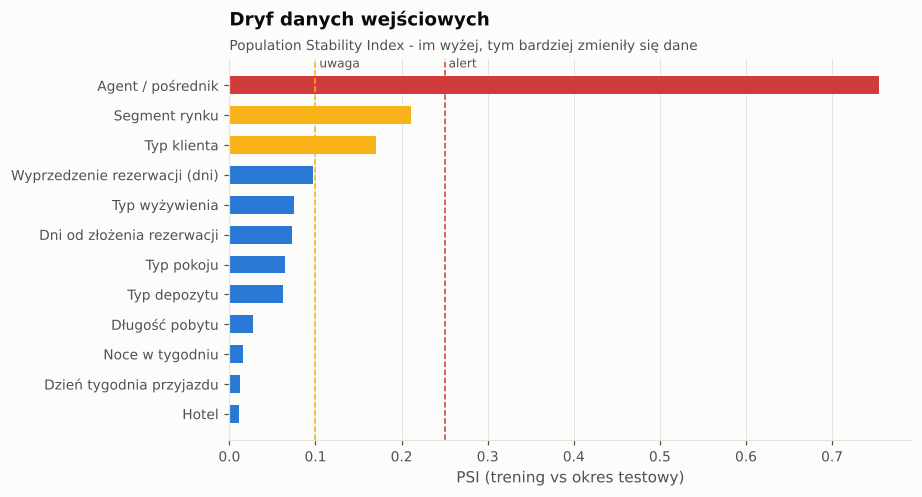

,Cecha,PSI,Status
0,Agent / pośrednik,"0,754",ALERT
1,Segment rynku,"0,211",Uwaga
2,Typ klienta,"0,170",Uwaga
3,Wyprzedzenie rezerwacji (dni),"0,097",OK
4,Typ wyżywienia,"0,075",OK
5,Dni od złożenia rezerwacji,"0,072",OK
6,Typ pokoju,"0,065",OK
7,Typ depozytu,"0,062",OK
8,Długość pobytu,"0,027",OK
9,Noce w tygodniu,"0,016",OK


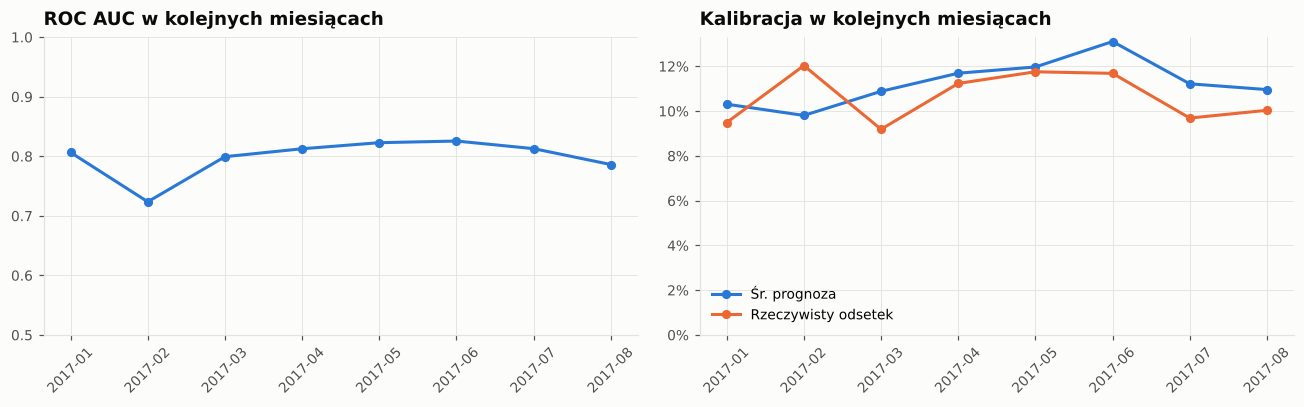

,Migawki,ROC AUC,Brier,Śr. prognoza,Rzeczywisty odsetek,Błąd kalibracji,Status
Miesiąc przyjazdu,,,,,,,
2017-01,11 384,"0,806","0,0704","10,3%","9,5%","0,8%",OK
2017-02,15 135,"0,724","0,0927","9,8%","12,0%","-2,2%",OK
2017-03,20 917,"0,799","0,0674","10,9%","9,2%","1,7%",OK
2017-04,23 740,"0,813","0,0788","11,7%","11,2%","0,5%",OK
2017-05,26 668,"0,823","0,0770","12,0%","11,8%","0,2%",OK
2017-06,25 433,"0,826","0,0718","13,1%","11,7%","1,4%",OK
2017-07,27 394,"0,813","0,0724","11,2%","9,7%","1,5%",OK
2017-08,25 092,"0,786","0,0762","11,0%","10,0%","0,9%",OK


In [12]:
show(F["drift"])
show(T["drift"], decimals={"PSI": 3}, max_rows=15)
show(F["monthly"])
show(T["monthly"], decimals={"ROC AUC": 3, "Brier": 4})

## 12. Założenia i ograniczenia

In [13]:
show(T["assumptions"])

,Wartość,Źródło
Założenie,,
Pojemność hotelu,maks. zrealizowane obłożenie,Szacunek z danych (zbiór nie zawiera liczby po...
Koszt relokacji gościa,2.0 x ADR + 150 EUR,SYNTETYCZNE
Wydatki dodatkowe na pokój-noc,"{'Resort Hotel': 35.0, 'City Hotel': 20.0}",SYNTETYCZNE
Noc wyprzedana (jest popyt odrzucony),>= 95% pojemności,SYNTETYCZNE
Popyt odrzucony w noc wyprzedaną,Poisson(10% pojemności),SYNTETYCZNE
Moment decyzji o overbookingu,D-3,Parametr
Polityka porównawcza,stały overbooking 5%,Parametr
Maks. efekt kontaktu z gościem,30% mniej anulacji,SYNTETYCZNE
Koszt kontaktu,1 EUR,SYNTETYCZNE


## 13. Eksport: raport HTML i Excel
Raport HTML (jeden plik z wykresami) można wysłać Klientowi; Excel zawiera pełne tabele.

In [ ]:
html_path = write_html(R)
xlsx_path = write_excel(R)
print(html_path)
print(xlsx_path)
# import webbrowser; webbrowser.open(html_path.resolve().as_uri())   # otwórz w przeglądarce